# 🎭 Comedy Show Attendance — Decision Tree Classification

**Machine Learning Assignment · Session 3**  
**Part A:** Synthetic data augmentation with **SDV**  
**Part B:** Decision tree comparison using **Gini impurity** and **entropy**

---

### Objective

Build a binary decision tree classifier to predict whether a comedian is likely to attend a comedy show (`Go`: `YES` or `NO`). Because the original dataset is extremely small, this notebook generates **100 synthetic training examples**, adds them to the real training observations, and compares two otherwise identical decision trees trained with different split criteria.

### Dataset at a glance

| Item | Description |
|:--|:--|
| Data file | `data.csv` |
| Real observations | **13** |
| Numerical predictors | `Age`, `Experience`, `Rank` |
| Categorical predictor | `Nationality` |
| Prediction target | `Go` (`YES` / `NO`) |
| Original target distribution | **7 `YES`**, **6 `NO`** |
| Synthetic sample size | **100** accepted rows |

### Experimental design

**Inspect the real data → split real observations → fit SDV on real training data only → validate synthetic records → augment training set → encode features → fit Gini and entropy trees → compare structure, importances, and test predictions.**

> **Methodological safeguard:** The real hold-out set is never used to fit the synthesizer, repair synthetic features, fit the encoder, or train either tree. This is especially important when evaluating the effect of synthetic data augmentation.


## 1. Imports and Setup

The following imports provide data manipulation and visualization tools, the **Synthetic Data Vault (SDV)** Gaussian copula synthesizer, basic distribution diagnostics, and the scikit-learn components needed for classification and evaluation.

**Environment:** This notebook requires `numpy`, `pandas`, `matplotlib`, `sdv`, `scipy`, and `scikit-learn`. The source dataset must be accessible under the exact filename `data.csv` in the working directory.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 2. Load and Inspect the Original Dataset

Load the comedian attendance data and inspect its shape, missing values, and class balance before modeling. These checks verify that the expected predictors and binary target are available and highlight the limitations of learning from just **13** examples.

**Expected output:** The input table, dataset dimensions, a missing-value summary, and the frequencies of `YES` and `NO` in `Go`.


In [17]:
DATA_PATH = "data.csv"
TARGET = "Go"

df = pd.read_csv(DATA_PATH)

display(df)

print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df[TARGET].value_counts())

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


Shape: (13, 5)

Missing values:
Age            0
Experience     0
Rank           0
Nationality    0
Go             0
dtype: int64

Target distribution:
Go
YES    7
NO     6
Name: count, dtype: int64


## 3. Create a Real-Data Hold-Out Set

A **stratified 80/20 train–test split** preserves the target classes as well as the sample size permits. With this dataset, the split contains **10 real training records** and **3 untouched real test records**.

The `RANDOM_STATE` parameter fixes the split for reproducibility. Crucially, splitting occurs **before synthetic-data generation**, so synthetic samples cannot be directly learned from the records that will later be used for testing.


In [18]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df[TARGET]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTraining target distribution:")
print(train_df[TARGET].value_counts())


Training shape: (10, 5)
Test shape: (3, 5)

Training target distribution:
Go
NO     5
YES    5
Name: count, dtype: int64


## 4. Part A — Generate Synthetic Data Using SDV

### Fit a Gaussian copula synthesizer on training data

The **GaussianCopulaSynthesizer** learns a probabilistic approximation of the joint relationships among columns in the **real training split**. It then samples new examples intended to resemble the underlying training-data distribution.

The implementation deliberately adds a **label-validity safeguard**:

1. Infer SDV metadata and fit the synthesizer using `train_df` only.
2. Draw candidate synthetic records in batches until **100 valid records** have been accepted.
3. Reject any generated row whose `Go` label is missing or is not one of the labels observed in the real training set.
4. Raise an error if 100 valid records cannot be collected within the configured batch limit.

> **Why this matters:** Synthetic records are generated **only for training**; the binary target is not imputed or overwritten during the validation process. Synthetic observations expand the sample count, but they do not create new independent ground-truth evidence.


In [19]:
SYNTHETIC_ROWS = 100
MAX_SAMPLING_BATCHES = 20

metadata = Metadata.detect_from_dataframes(
    data={"comedian": train_df}
)

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit({"comedian": train_df})

allowed_targets = set(train_df[TARGET].dropna().unique())
accepted_batches = []
accepted_count = 0
rejected_count = 0

for batch_number in range(1, MAX_SAMPLING_BATCHES + 1):
    remaining = SYNTHETIC_ROWS - accepted_count

    new_batch = synthesizer.sample(
        num_rows=remaining
    )["comedian"]

    if not isinstance(new_batch, pd.DataFrame):
        raise TypeError("The SDV single-table sampler must return a DataFrame.")
    if list(new_batch.columns) != list(train_df.columns):
        raise ValueError("Synthetic columns differ from the training data.")

    # Missing and unfamiliar labels are rejected; they are never imputed.
    valid_target_mask = new_batch[TARGET].isin(allowed_targets)
    rejected_count += int((~valid_target_mask).sum())

    accepted = new_batch.loc[valid_target_mask].copy()
    accepted_batches.append(accepted)
    accepted_count += len(accepted)

    if accepted_count >= SYNTHETIC_ROWS:
        break

if accepted_count < SYNTHETIC_ROWS:
    raise RuntimeError(
        f"Only {accepted_count}/{SYNTHETIC_ROWS} valid synthetic rows were generated "
        f"after {MAX_SAMPLING_BATCHES} sampling batches. "
        "Check SDV metadata and the generated target distribution."
    )

synthetic_data = pd.concat(accepted_batches, ignore_index=True).iloc[
    :SYNTHETIC_ROWS
].copy()

assert len(synthetic_data) == SYNTHETIC_ROWS
assert synthetic_data[TARGET].isin(allowed_targets).all()

print("Synthetic shape:", synthetic_data.shape)
print("Rejected synthetic rows with invalid target labels:", rejected_count)
print("Sampling batches used:", batch_number)

display(synthetic_data.head())

Synthetic shape: (100, 5)
Rejected synthetic rows with invalid target labels: 0
Sampling batches used: 1


c:\Users\f.azadi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


,Age,Experience,Rank,Nationality,Go
0,14181860,20,8,UK,YES
1,4508385,19,8,UK,YES
2,2456481,10,8,N,NO
3,10082789,15,7,UK,YES
4,11672438,15,7,UK,YES


### Initial synthetic-data checks

Before applying any feature-level corrections, inspect **missing values** and the synthetic `Go` distribution. This provides a quick diagnostic of the data produced by the generative model and reveals whether either target class is disproportionately represented.


In [20]:
print("Missing values before feature corrections:")
print(synthetic_data.isnull().sum())

print("\nSynthetic target distribution:")
print(synthetic_data[TARGET].value_counts())

Missing values before feature corrections:
Age            0
Experience     0
Rank           0
Nationality    0
Go             0
dtype: int64

Synthetic target distribution:
Go
YES    58
NO     42
Name: count, dtype: int64


### Validate and repair synthetic predictors

A synthetic sample can be statistically plausible while violating simple domain constraints. The following code applies conservative, **training-derived** corrections to the generated *predictors*:

- **Numeric fields:** Coerce to numeric values, fill missing entries with the corresponding real-training median, constrain values to the real-training range, and preserve integer data types when appropriate.
- **Experience constraint:** Require nonnegative experience and prevent `Experience` from exceeding `Age`.
- **Nationality:** Replace unseen or missing categories with the real-training mode.
- **Target integrity:** Keep the synthesized `Go` values unchanged and assert that only allowed labels remain.

No correction rule is estimated from the held-out test data. These checks enforce basic consistency; they do **not** prove that the synthetic examples preserve every real-world relationship.


In [21]:
synthetic_data = synthetic_data.copy()

numeric_columns = ["Age", "Experience", "Rank"]
feature_categories = ["Nationality"]

for column in numeric_columns:
    training_median = train_df[column].median()
    training_min = train_df[column].min()
    training_max = train_df[column].max()

    synthetic_data[column] = pd.to_numeric(
        synthetic_data[column], errors="coerce"
    ).fillna(training_median)

    synthetic_data[column] = synthetic_data[column].clip(
        lower=training_min,
        upper=training_max
    )

    if pd.api.types.is_integer_dtype(train_df[column].dtype):
        synthetic_data[column] = (
            synthetic_data[column].round().astype(train_df[column].dtype)
        )

# Only synthetic features are corrected; Go is never overwritten.
synthetic_data["Experience"] = synthetic_data["Experience"].clip(lower=0)
synthetic_data["Experience"] = synthetic_data[
    ["Experience", "Age"]
].min(axis=1)

for column in feature_categories:
    valid_values = train_df[column].dropna().unique()
    training_mode = train_df[column].mode(dropna=True).iloc[0]
    synthetic_data[column] = synthetic_data[column].where(
        synthetic_data[column].isin(valid_values),
        training_mode
    )

assert synthetic_data[TARGET].isin(allowed_targets).all()
assert synthetic_data.isnull().sum().sum() == 0

print("Synthetic data after training-only feature checks:")
display(synthetic_data.head())
print("\nRemaining missing values:")
print(synthetic_data.isnull().sum())


Synthetic data after training-only feature checks:


,Age,Experience,Rank,Nationality,Go
0,66,20,8,UK,YES
1,66,19,8,UK,YES
2,66,10,8,N,NO
3,66,15,7,UK,YES
4,66,15,7,UK,YES



Remaining missing values:
Age            0
Experience     0
Rank           0
Nationality    0
Go             0
dtype: int64


## 5. Assess Synthetic-Data Fidelity

Before incorporating the generated rows into training, compare them with the **real training set**, not the test set.

| Diagnostic | Interpretation |
|:--|:--|
| Mean, median, standard deviation | Compare the central tendency and spread of numerical variables. |
| Overlaid histograms | Reveal broad differences in the distributions of `Age`, `Experience`, and `Rank`. |
| Kolmogorov–Smirnov (KS) statistic | Quantifies the largest distance between the empirical cumulative distributions of a numerical feature; **0** means no observed distance. |
| Total variation (TV) distance | Measures categorical-proportion differences for `Nationality` and `Go`; **0** means identical observed category proportions. |

For categorical distributions, the calculated total variation distance is

\[
D_{\mathrm{TV}}(P,Q)=\frac{1}{2}\sum_{c}|P(c)-Q(c)|.
\]

**Interpretation:** Smaller KS and TV distances indicate closer *marginal* distributions. Because this assessment does not validate all joint or conditional relationships, it should be interpreted as a diagnostic rather than a certification of synthetic-data quality.


Numerical distribution diagnostics:


,Training mean,Synthetic mean,Training median,Synthetic median,Training std,Synthetic std,KS distance (0=similar)
Feature,,,,,,,
Age,38.3,66.00,39.0,66.0,14.492,0.000,0.90
Experience,9.7,13.62,11.0,14.0,6.219,5.112,0.38
Rank,6.7,6.64,7.0,6.0,1.703,1.404,0.15


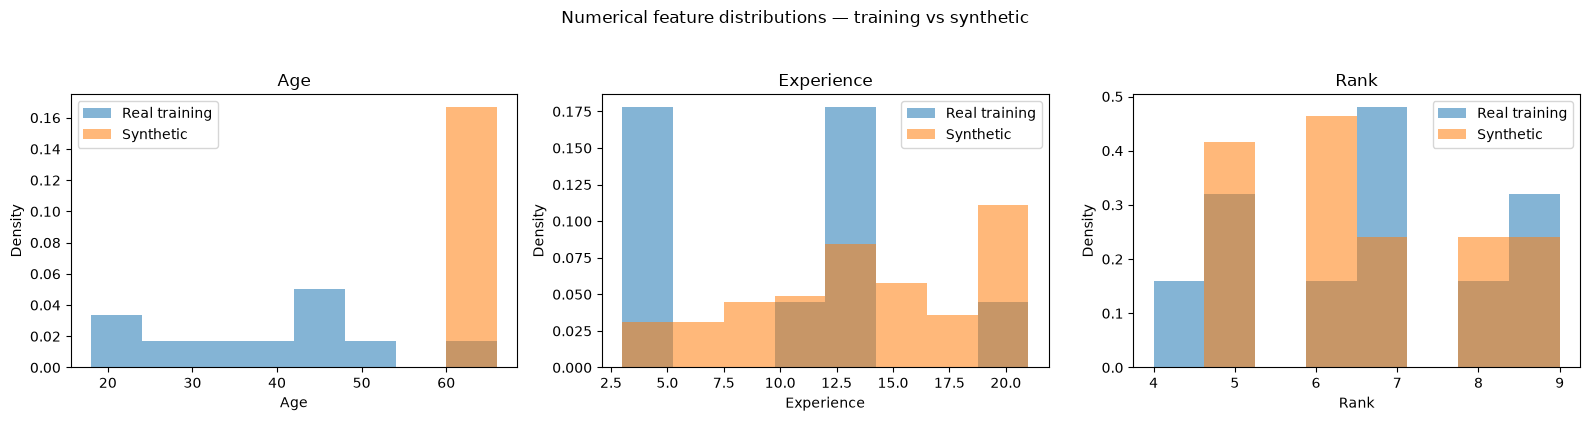

Categorical distribution diagnostics:


,TV distance (0=similar)
Feature,
Nationality,0.23
Go,0.08



Category proportions — Nationality:


,Real training,Synthetic
Nationality,,
N,0.3,0.11
UK,0.4,0.63
USA,0.3,0.26



Category proportions — Go:


,Real training,Synthetic
Go,,
NO,0.5,0.42
YES,0.5,0.58


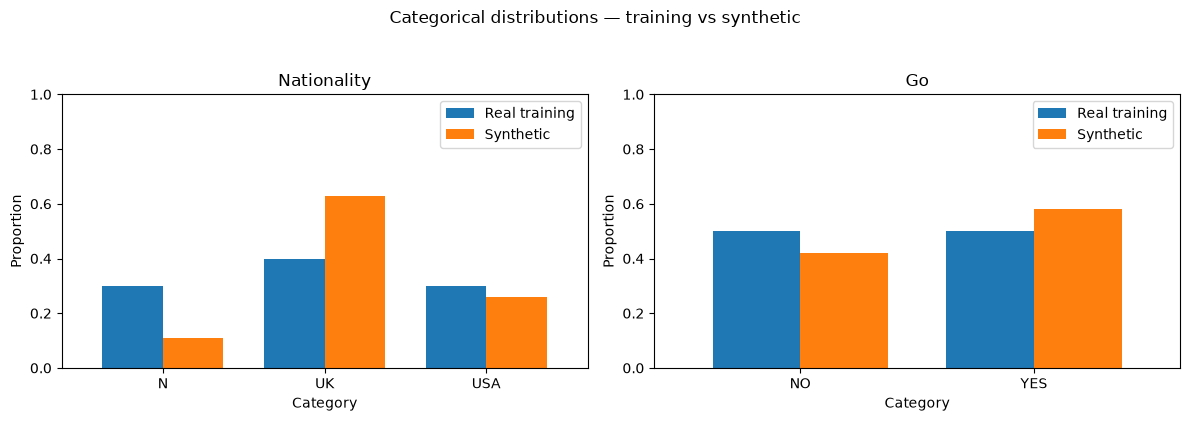

Note: quality diagnostics use only real training rows; the held-out test set is never inspected here.


In [22]:
# Compare numerical distributions using training rows only.
numeric_quality_rows = []
for column in numeric_columns:
    real_values = train_df[column].dropna()
    fake_values = synthetic_data[column].dropna()

    numeric_quality_rows.append({
        "Feature": column,
        "Training mean": real_values.mean(),
        "Synthetic mean": fake_values.mean(),
        "Training median": real_values.median(),
        "Synthetic median": fake_values.median(),
        "Training std": real_values.std(),
        "Synthetic std": fake_values.std(),
        "KS distance (0=similar)": ks_2samp(real_values, fake_values).statistic,
    })

numeric_quality = pd.DataFrame(numeric_quality_rows).set_index("Feature")
print("Numerical distribution diagnostics:")
display(numeric_quality.round(3))

fig, axes = plt.subplots(1, len(numeric_columns), figsize=(16, 4))
for ax, column in zip(axes, numeric_columns):
    bins = np.linspace(
        train_df[column].min(), train_df[column].max(), num=9
    )
    ax.hist(
        train_df[column], bins=bins, density=True,
        alpha=0.55, label="Real training"
    )
    ax.hist(
        synthetic_data[column], bins=bins, density=True,
        alpha=0.55, label="Synthetic"
    )
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Numerical feature distributions — training vs synthetic", y=1.04)
plt.tight_layout()
plt.show()

# Compare categorical proportions, including the target Go.
categorical_quality_rows = []
categorical_proportions = {}
for column in ["Nationality", TARGET]:
    categories = sorted(
        set(train_df[column].dropna().unique())
        | set(synthetic_data[column].dropna().unique())
    )
    real_share = (
        train_df[column].value_counts(normalize=True)
        .reindex(categories, fill_value=0.0)
    )
    fake_share = (
        synthetic_data[column].value_counts(normalize=True)
        .reindex(categories, fill_value=0.0)
    )
    categorical_proportions[column] = pd.DataFrame({
        "Real training": real_share,
        "Synthetic": fake_share,
    })
    tv_distance = 0.5 * (real_share - fake_share).abs().sum()
    categorical_quality_rows.append({
        "Feature": column,
        "TV distance (0=similar)": tv_distance
    })

categorical_quality = pd.DataFrame(categorical_quality_rows).set_index("Feature")
print("Categorical distribution diagnostics:")
display(categorical_quality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["Nationality", TARGET]):
    print(f"\nCategory proportions — {column}:")
    display(categorical_proportions[column].round(3))
    categorical_proportions[column].plot(kind="bar", ax=ax, width=0.75)
    ax.set_title(column)
    ax.set_xlabel("Category")
    ax.set_ylabel("Proportion")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
    ax.legend()
plt.suptitle("Categorical distributions — training vs synthetic", y=1.04)
plt.tight_layout()
plt.show()

print(
    "Note: quality diagnostics use only real training rows; "
    "the held-out test set is never inspected here."
)


## 6. Augment the Real Training Split

Combine the **10 original training rows** with the **100 accepted synthetic rows**, then shuffle the augmented training dataset. The resulting training set should contain **110 rows**, while the **3 real test rows remain untouched**.

The class counts printed here help assess whether synthesis altered the relative frequency of the attendance labels.


In [23]:
train_augmented = pd.concat(
    [train_df, synthetic_data],
    ignore_index=True
)

train_augmented = train_augmented.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

print("Real training rows:", len(train_df))
print("Synthetic rows:", len(synthetic_data))
print("Augmented training rows:", len(train_augmented))
print("Untouched real test rows:", len(test_df))

print("\nTarget distribution in real training data:")
print(train_df[TARGET].value_counts())

print("\nTarget distribution in synthetic data:")
print(synthetic_data[TARGET].value_counts())

print("\nTarget distribution after augmentation:")
print(train_augmented[TARGET].value_counts())

display(train_augmented.head())

Real training rows: 10
Synthetic rows: 100
Augmented training rows: 110
Untouched real test rows: 3

Target distribution in real training data:
Go
NO     5
YES    5
Name: count, dtype: int64

Target distribution in synthetic data:
Go
YES    58
NO     42
Name: count, dtype: int64

Target distribution after augmentation:
Go
YES    63
NO     47
Name: count, dtype: int64


,Age,Experience,Rank,Nationality,Go
0,66,14,9,UK,NO
1,66,20,8,UK,YES
2,35,14,9,UK,YES
3,66,10,5,UK,YES
4,66,17,6,UK,YES


## 7. Separate Predictors and Labels

Construct the feature matrix `X` and target vector `y` for the augmented training set and the untouched real test set. The response variable is **`Go`**, while `Age`, `Experience`, `Rank`, and `Nationality` are treated as predictors.

This separation ensures that the target itself is never inadvertently passed to the classifier as a feature.


In [24]:
X_train = train_augmented.drop(columns=[TARGET])
y_train = train_augmented[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (110, 4)
y_train shape: (110,)
X_test shape: (3, 4)
y_test shape: (3,)


## 8. Prepare Categorical Features

Decision tree estimators in scikit-learn require numeric input. The `ColumnTransformer` therefore **one-hot encodes** `Nationality` and passes through the three numerical predictors unchanged.

The encoder is **fitted exclusively on augmented training features**, then reused to transform the real test set; `handle_unknown="ignore"` avoids failures if a previously unseen nationality occurs during testing.

After transformation, the notebook retains readable feature names so the learned splits and feature importances can be interpreted.


In [25]:
categorical_features = ["Nationality"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "nationality",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)
print("\nEncoded features:")
print(list(feature_names))

display(X_train_encoded.head())

Encoded training shape: (110, 6)
Encoded test shape: (3, 6)

Encoded features:
['Nationality_N', 'Nationality_UK', 'Nationality_USA', 'Age', 'Experience', 'Rank']


,Nationality_N,Nationality_UK,Nationality_USA,Age,Experience,Rank
0,0.0,1.0,0.0,66.0,14.0,9.0
1,0.0,1.0,0.0,66.0,20.0,8.0
2,0.0,1.0,0.0,35.0,14.0,9.0
3,0.0,1.0,0.0,66.0,10.0,5.0
4,0.0,1.0,0.0,66.0,17.0,6.0


## 9. Part B — Fit the Gini Decision Tree

A decision tree recursively divides its training data into increasingly homogeneous groups. The first model selects splits using **Gini impurity**, which measures the degree of class mixing at a node:

\[
Gini(t)=1-\sum_{k=1}^{K}p(k\mid t)^2
\]

Here, \(p(k\mid t)\) is the proportion of records in node \(t\) belonging to class \(k\). A pure node has a Gini impurity of **0**. At each split, the tree looks for the greatest **weighted reduction in child-node impurity**.

The Gini model uses the same training data and `RANDOM_STATE` as the entropy model, isolating the **split criterion** as the primary experimental difference.


In [26]:
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE
)

gini_tree.fit(
    X_train_encoded,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

## 10. Fit the Entropy Decision Tree

The second classifier changes only the criterion from `gini` to **`entropy`**. Entropy measures class uncertainty rather than the probability-based mixing used by Gini:

\[
H(t)=-\sum_{k=1}^{K}p(k\mid t)\log_{2}p(k\mid t),
\]

with \(0\log_2 0\) defined as **0**. The model chooses splits that maximize the **weighted reduction in entropy**, also known as *information gain*.

Both criteria encourage purer child nodes, but they score candidate partitions differently. As a result, their preferred splits, tree shapes, and feature-importance rankings **may** differ; they are not guaranteed to differ on every dataset.


In [27]:
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=RANDOM_STATE
)

entropy_tree.fit(
    X_train_encoded,
    y_train
)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

## 11. Compare the Learned Tree Structures

Evaluate whether the split criterion changed the model's learned architecture. The comparison table reports four directly observable properties:

| Property | What it tells us |
|:--|:--|
| **Depth** | Length of the longest root-to-leaf path. |
| **Number of leaves** | Count of terminal prediction nodes. |
| **Number of nodes** | Total count of split and leaf nodes. |
| **Root feature** | Predictor selected for the very first decision. |

These are **observed model properties**, not theoretical assumptions about which criterion must produce the deeper or simpler tree. Interpret the printed table after running the notebook.


In [28]:
def get_root_feature(model, feature_names):
    root_index = model.tree_.feature[0]

    if root_index < 0:
        return "No split (root is a leaf)"

    return feature_names[root_index]


gini_root = get_root_feature(
    gini_tree,
    feature_names
)

entropy_root = get_root_feature(
    entropy_tree,
    feature_names
)

structure_comparison = pd.DataFrame(
    {
        "Gini": [
            gini_tree.get_depth(),
            gini_tree.get_n_leaves(),
            gini_tree.tree_.node_count,
            gini_root
        ],
        "Entropy": [
            entropy_tree.get_depth(),
            entropy_tree.get_n_leaves(),
            entropy_tree.tree_.node_count,
            entropy_root
        ]
    },
    index=[
        "Depth",
        "Number of Leaves",
        "Number of Nodes",
        "Root Feature"
    ]
)

display(structure_comparison)

,Gini,Entropy
Depth,13,14
Number of Leaves,52,53
Number of Nodes,103,105
Root Feature,Rank,Rank


### Gini tree — visual inspection

Visualize the complete tree trained with Gini impurity. Node labels show the split condition, impurity score, sample count, and class composition; the colors indicate the prevailing predicted class.

**What to inspect:** The first split, how numerical thresholds are selected, the number of terminal leaves, and whether any branches isolate very few records.


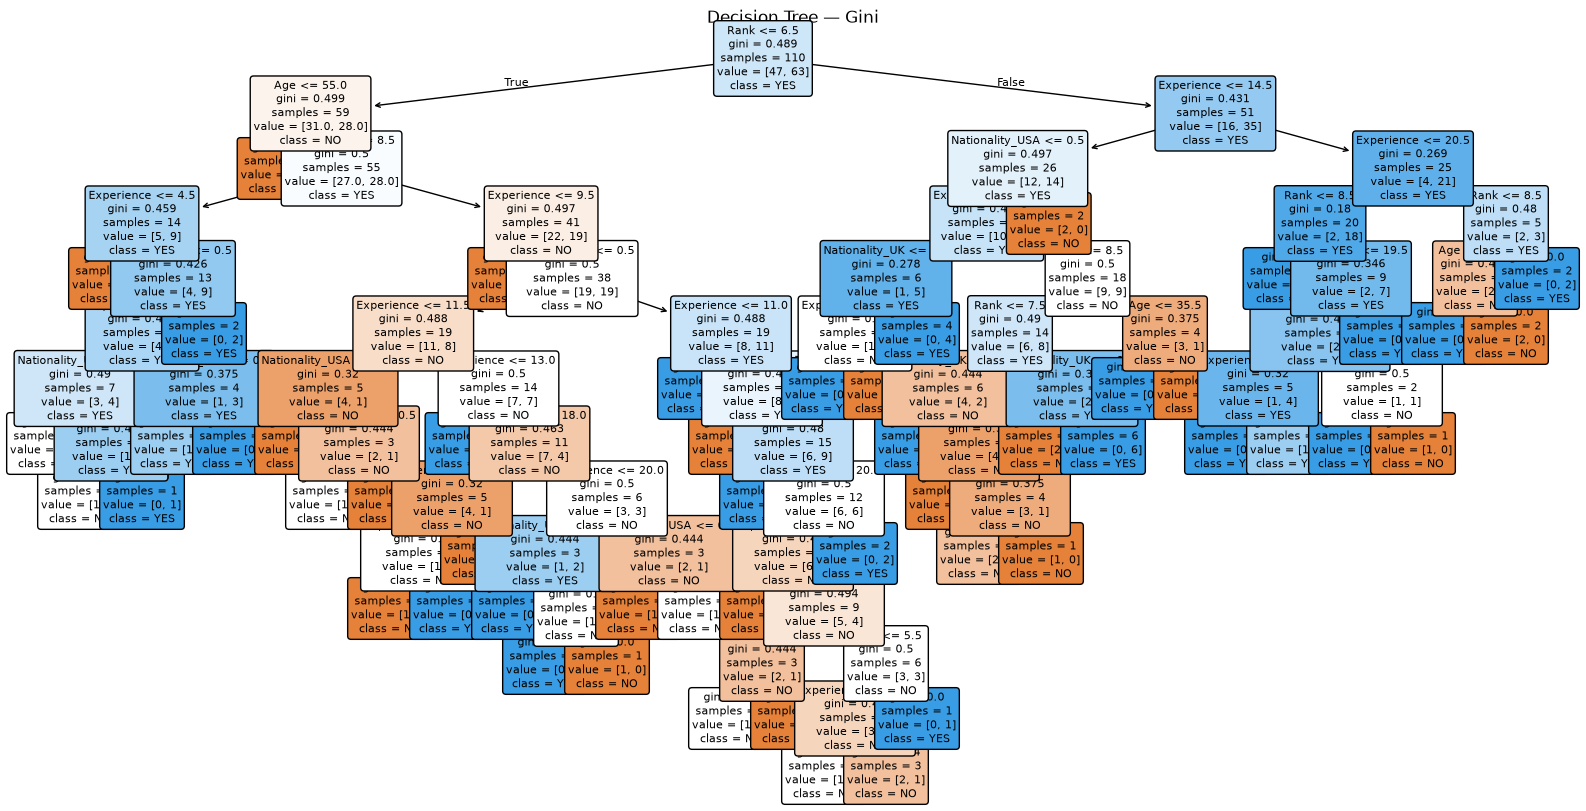

In [29]:
plt.figure(figsize=(20, 10))

plot_tree(
    gini_tree,
    feature_names=feature_names,
    class_names=gini_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree — Gini")
plt.show()

### Entropy tree — visual inspection

Visualize the entropy-based tree with the same feature names and display settings. Compare it side by side with the Gini plot for changed split thresholds, reordered predictors, or differences in overall branching complexity.

A visual difference describes **how the model learned**; it does not by itself establish that one model generalizes better than the other.


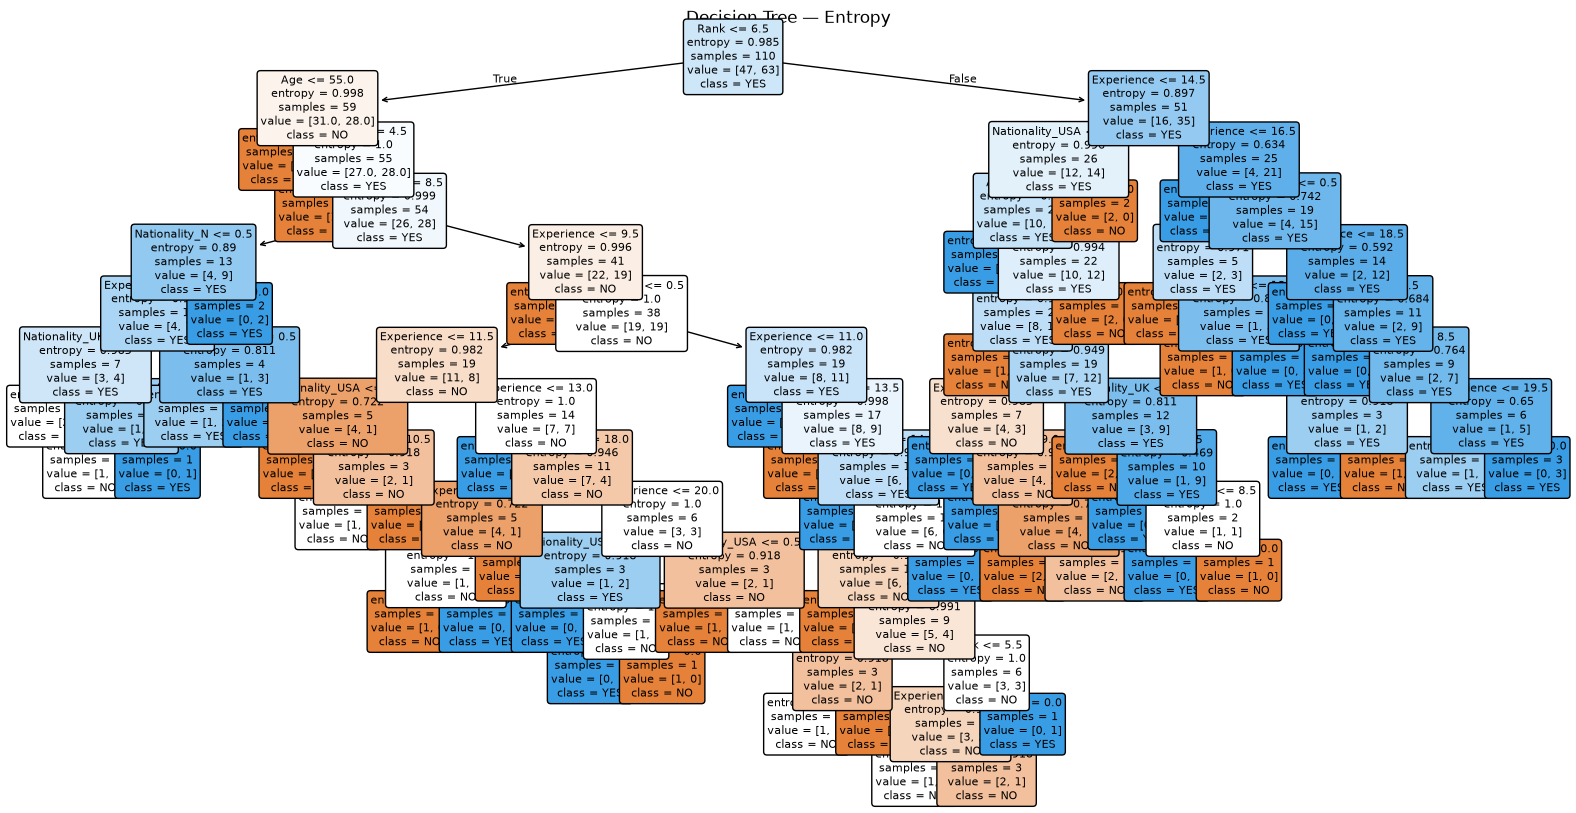

In [30]:
plt.figure(figsize=(20, 10))

plot_tree(
    entropy_tree,
    feature_names=feature_names,
    class_names=entropy_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree — Entropy")
plt.show()

## 12. Compare Feature Importances

The `feature_importances_` values in scikit-learn summarize the **normalized total weighted impurity reduction** attributable to each feature in the fitted tree. They are **model-specific**, so replacing Gini impurity with entropy can change their values or ranking.

Because one-hot encoding splits `Nationality` into multiple indicator columns, the notebook **sums their individual importances back into the original `Nationality` feature**. This makes the comparison fairer and easier to interpret at the original-predictor level.

The resulting table presents both models' importance scores and their **absolute differences**, ordered by the largest discrepancy.

> **Caution:** Impurity-based feature importance describes the fitted trees, not a causal relationship. It can also be unstable with such a small original dataset.


In [31]:
feature_importances = pd.DataFrame({
    "Feature": feature_names,
    "Gini": gini_tree.feature_importances_,
    "Entropy": entropy_tree.feature_importances_
})

feature_importances["Original Feature"] = (
    feature_importances["Feature"]
    .map(
        lambda name:
        "Nationality"
        if name.startswith("Nationality_")
        else name
    )
)

aggregated_importance = (
    feature_importances
    .groupby("Original Feature")[["Gini", "Entropy"]]
    .sum()
)

aggregated_importance["Absolute Difference"] = (
    aggregated_importance["Gini"]
    - aggregated_importance["Entropy"]
).abs()

aggregated_importance = aggregated_importance.sort_values(
    "Absolute Difference",
    ascending=False
)

display(aggregated_importance)

,Gini,Entropy,Absolute Difference
Original Feature,,,
Experience,0.496336,0.565314,0.068978
Nationality,0.201512,0.158992,0.042520
Rank,0.187313,0.169677,0.017637
Age,0.114839,0.106017,0.008821


## 13. Evaluate Both Trees on Real Hold-Out Data

Use the **same untouched real test split** to calculate predictions, accuracy, per-class precision/recall/F1 scores, and confusion matrices for both classifiers.

This directly compares the predictive behavior of the Gini and entropy models under identical evaluation conditions. However, the held-out sample contains only **3 records**, so even one different prediction changes the reported accuracy by approximately **33.3 percentage points**.

**Evaluation priority:** Read the confusion matrices and classification reports together with accuracy. Avoid drawing strong conclusions about expected real-world performance from this very small test set.


In [32]:
gini_predictions = gini_tree.predict(
    X_test_encoded
)

entropy_predictions = entropy_tree.predict(
    X_test_encoded
)

evaluation = pd.DataFrame(
    {
        "Model": [
            "Decision Tree — Gini",
            "Decision Tree — Entropy"
        ],
        "Test Accuracy": [
            accuracy_score(y_test, gini_predictions),
            accuracy_score(y_test, entropy_predictions)
        ]
    }
)

display(evaluation)

print("Gini classification report:")
print(
    classification_report(
        y_test,
        gini_predictions,
        zero_division=0
    )
)

print("Entropy classification report:")
print(
    classification_report(
        y_test,
        entropy_predictions,
        zero_division=0
    )
)

labels = sorted(y_train.unique())

print("Gini confusion matrix:")
print(
    confusion_matrix(
        y_test,
        gini_predictions,
        labels=labels
    )
)

print("\nEntropy confusion matrix:")
print(
    confusion_matrix(
        y_test,
        entropy_predictions,
        labels=labels
    )
)

,Model,Test Accuracy
0,Decision Tree — Gini,0.333333
1,Decision Tree — Entropy,0.666667


Gini classification report:
              precision    recall  f1-score   support

          NO       0.33      1.00      0.50         1
         YES       0.00      0.00      0.00         2

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

Entropy classification report:
              precision    recall  f1-score   support

          NO       0.50      1.00      0.67         1
         YES       1.00      0.50      0.67         2

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3

Gini confusion matrix:
[[1 0]
 [2 0]]

Entropy confusion matrix:
[[1 0]
 [1 1]]


## 14. Part B — Required Two-to-Three-Sentence Answer

The assignment asks for a short explanation of **(1) how Gini works** and **(2) what actually differs between the Gini and entropy models**. Instead of inserting unverified numerical claims, the next **unchanged code cell** constructs a **three-sentence, data-driven answer** using the trained models.

Its printed response reports the observed **depth, leaf count, root feature, most important feature for each criterion, and largest absolute feature-importance difference**. This makes the written conclusion consistent with the results of the actual notebook run.


In [33]:
gini_top_feature = aggregated_importance["Gini"].idxmax()
entropy_top_feature = aggregated_importance["Entropy"].idxmax()

gini_top_value = aggregated_importance.loc[
    gini_top_feature,
    "Gini"
]

entropy_top_value = aggregated_importance.loc[
    entropy_top_feature,
    "Entropy"
]

largest_difference_feature = (
    aggregated_importance["Absolute Difference"].idxmax()
)

largest_difference_value = aggregated_importance.loc[
    largest_difference_feature,
    "Absolute Difference"
]

final_answer = (
    "Gini impurity measures how mixed the classes are in a node; lower Gini means a purer node, "
    "and the tree selects splits that maximize the reduction in weighted impurity. "
    f"In this run, the Gini tree had depth {gini_tree.get_depth()}, "
    f"{gini_tree.get_n_leaves()} leaves, and root feature '{gini_root}', whereas the Entropy tree "
    f"had depth {entropy_tree.get_depth()}, {entropy_tree.get_n_leaves()} leaves, and root feature "
    f"'{entropy_root}'. "
    f"The top feature was '{gini_top_feature}' for Gini ({gini_top_value:.3f}) and "
    f"'{entropy_top_feature}' for Entropy ({entropy_top_value:.3f}); the largest absolute "
    f"importance difference was for '{largest_difference_feature}' ({largest_difference_value:.3f})."
)

print(final_answer)

Gini impurity measures how mixed the classes are in a node; lower Gini means a purer node, and the tree selects splits that maximize the reduction in weighted impurity. In this run, the Gini tree had depth 13, 52 leaves, and root feature 'Rank', whereas the Entropy tree had depth 14, 53 leaves, and root feature 'Rank'. The top feature was 'Experience' for Gini (0.496) and 'Experience' for Entropy (0.565); the largest absolute importance difference was for 'Experience' (0.069).


---

## 15. Conclusion and Limitations

This notebook completes the two parts of the exercise: **SDV-based augmentation followed by decision tree training**, and an **otherwise controlled comparison between Gini impurity and entropy**. The structure tables, tree diagrams, aggregated importance scores, and test metrics provide the evidence needed to answer Part B.

**Important limitations:** The original data contains only **13 real examples**; the **100 generated records are not independent real observations**; a **three-row test set** makes performance estimates highly variable; and the SDV sampler is not explicitly seeded in the original code, so its generated values and downstream comparisons may differ between executions. Interpret observed differences as **specific to this run**, not universal advantages of either impurity criterion.

**Reproduction:** Keep `data.csv` beside this notebook, install the listed Python dependencies, and run the cells from top to bottom. No original code cells have been modified.
